# 04 — Verdieping: SARIMA

Deze notebook hoort bij [`docs/methodologie/sarima.md`](../docs/methodologie/sarima.md).
SARIMA is de tijdreeks in het cumulatieve en individuele spoor. Het voorspelt hoe de
aanmeldcurve na de peilweek verder loopt. We:

1. **Trainen en voorspellen** voor één opleiding/herkomst
2. Een **predictie-interval** (80% en 95%) plotten
3. De voorspelling naast de **werkelijke curve** leggen
4. De **aannames** op data checken


> 🧭 **Verdieping: een ander spoor.** Het aanbevolen model is het
> [CWF-model](02_cwf_model.ipynb): het is doorgaans nauwkeuriger en
> geeft er een onzekerheidsmarge en betrouwbaarheidslabel bij. Deze notebook legt
> een van de andere sporen uit. Die zijn nog steeds te gebruiken (`-d c`, `-d i`,
> `-d b`), bijvoorbeeld om te vergelijken.


> ℹ️ **Over de demodata.** De notebooks draaien op de meegeleverde, synthetische
> demodata in `data/input/`. Daarin staan de aanmeldingen van alle instellingen
> per opleiding opgeteld, net zoals de pipeline dat doet zonder `institution_filter`.
> Opleidingen zijn **Isatcodes** (bijv. `56604` = B Psychologie); waar het helpt
> staat de naam erachter.
>
> Twee eigenaardigheden van de demodata: **inschrijvingen zijn altijd 0** en
> **de aanmelders zakken vanaf eind mei (rond week 23) kunstmatig in**. Daarom
> gebruiken de notebooks een vroege peilweek (12). Op echte telbestanden speelt dit niet.
>
> **Met eigen data:** vervang de bestanden in `data/input/` en pas `PROGRAMMA`,
> `PREDICT_YEAR` en `PREDICT_WEEK` aan.


In [1]:
# --- Standaard setup voor alle studentprognose-notebooks ---
import sys
from pathlib import Path

# Maak _helpers.py importeerbaar en ga naar projectroot
NOTEBOOKS_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOKS_DIR))

from _helpers import project_root, setup_matplotlib  # noqa: E402
project_root()
setup_matplotlib()

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print("Projectmap gevonden:", "ja" if Path("data/input").is_dir() else "nee — start Jupyter vanuit de repo")
print("Python:", sys.version.split()[0])


Projectmap gevonden: ja
Python: 3.12.12


## 1. Wat is SARIMA, in gewoon Nederlands

Aanmelddata heeft twee eigenschappen:

- **Een sterke jaarcyclus**: de zomer is rustig, januari–mei is druk.
- **Sterke samenhang van week tot week**: week T lijkt op week T-1.

SARIMA combineert beide:

$$\text{SARIMA}(p,d,q)(P,D,Q)_{s}$$

| Component | Wat doet het? | Wat betekent het hier? |
|-----------|---------------|------------------------|
| `p` (AR) | Autoregressie op korte termijn | Hoe sterk hangt week T af van week T-1 |
| `d` (I)  | Differentiëren | Trend wegfilteren |
| `q` (MA) | Voortschrijdend gemiddelde van fouten | Dempt ruis |
| `(P,D,Q)_s` | Hetzelfde, op de seizoenslag | Vergelijk een week met dezelfde week vorig jaar |

De seizoenslengte `s` is het aantal weken per jaar in de data (meestal 52; minder
als er weken ontbreken). De ordes zijn **vast**:


In [2]:
from studentprognose.utils.constants import (
    SARIMA_ORDER, SARIMA_SEASONAL_ORDER,
    SARIMA_ORDER_INDIVIDUAL, SARIMA_SEASONAL_ORDER_ALT,
)
print(f"Cumulatief spoor:  order={SARIMA_ORDER}, seasonal_order={SARIMA_SEASONAL_ORDER}")
print(f"Individueel spoor: order={SARIMA_ORDER_INDIVIDUAL}, seasonal_order={SARIMA_SEASONAL_ORDER_ALT}")


Cumulatief spoor:  order=(1, 0, 1), seasonal_order=(1, 1, 1, 52)
Individueel spoor: order=(1, 1, 1), seasonal_order=(1, 1, 0, 52)


In [3]:
from _helpers import load_cumulative, opleidingsnamen, label

data_cumulative, data_studentcount, data_cumulative_raw = load_cumulative()
NAMEN = opleidingsnamen()
print(f"Telregels (opgeteld over instellingen): {len(data_cumulative):,}")
print(f"Aantal opleidingen:                     {data_cumulative['Croho groepeernaam'].nunique()}")
print(f"Collegejaren:                           {data_cumulative['Collegejaar'].min()}–{data_cumulative['Collegejaar'].max()}")
print(f"Realisatie (studentaantallen):          {len(data_studentcount):,} rijen")


Telregels (opgeteld over instellingen): 64,947
Aantal opleidingen:                     393
Collegejaren:                           2020–2026
Realisatie (studentaantallen):          2,934 rijen


## 2. Trainingsreeks bouwen

We plakken de jaren achter elkaar tot één lange reeks die eindigt op peilweek 12 van
2023. Weken ná de peilweek waren op dat moment nog niet bekend en gaan er vooraf uit.
Dit zijn dezelfde stappen als in de pipeline.


In [4]:
from studentprognose.config import load_defaults
from studentprognose.data.transforms import drop_weeks_after_predict_week, ensure_start_week
from studentprognose.models.sarima import _get_transformed_data, split_time_series
from studentprognose.utils.weeks import get_all_weeks_valid
from statsforecast.models import ARIMA

PROGRAMMA = 56604  # B Psychologie
HERKOMST = "NL"
EXAMENTYPE = "Bachelor"
PREDICT_YEAR = 2023
PREDICT_WEEK = 12
MIN_TRAINING_YEAR = load_defaults()["model_config"].get("min_training_year", 2016)


def reeks_voor(df):
    wide = _get_transformed_data(df, min_training_year=MIN_TRAINING_YEAR)
    wide = wide[
        (wide["Croho groepeernaam"] == PROGRAMMA)
        & (wide["Herkomst"] == HERKOMST)
        & (wide["Examentype"] == EXAMENTYPE)
        & (wide["Collegejaar"] <= PREDICT_YEAR)
    ]
    return ensure_start_week(wide)


subset = reeks_voor(drop_weeks_after_predict_week(data_cumulative.copy(), PREDICT_YEAR, PREDICT_WEEK))
ts_data, target_weeks = split_time_series(subset, PREDICT_YEAR, PREDICT_WEEK)
PERIODE = len(get_all_weeks_valid(subset.columns))

print(f"Trainingsreeks: {ts_data.size} weken (~{ts_data.size / PERIODE:.1f} jaar van {PERIODE} weken)")
print(f"Voorspelhorizon: {len(target_weeks)} weken (week {target_weeks[0]} t/m {target_weeks[-1]})")


Trainingsreeks: 150 weken (~3.5 jaar van 43 weken)
Voorspelhorizon: 22 weken (week 13 t/m 34)


## 3. Model en predictie-interval

We gebruiken `statsforecast.ARIMA` rechtstreeks (dezelfde basis als de pipeline), zodat
we naast de puntvoorspelling ook 80%- en 95%-intervallen krijgen.


In [5]:
model = ARIMA(order=SARIMA_ORDER, season_length=PERIODE, seasonal_order=SARIMA_SEASONAL_ORDER[:3])
model.fit(y=ts_data)
fc = model.predict(h=len(target_weeks), level=[80, 95])

forecast_table = pd.DataFrame({
    "week": target_weeks,
    "voorspelling": np.asarray(fc["mean"]).round(1),
    "lo 95%": np.asarray(fc["lo-95"]).round(1),
    "hi 95%": np.asarray(fc["hi-95"]).round(1),
})
forecast_table.head(10)


,week,voorspelling,lo 95%,hi 95%
0,13,1383.0,1306.9,1459.0
1,14,1536.2,1431.5,1640.9
2,15,1647.0,1520.9,1773.1
3,16,1833.6,1690.0,1977.2
4,17,1973.5,1815.0,2132.1
5,18,2150.6,1979.0,2322.2
6,19,2294.9,2111.6,2478.1
7,20,2391.9,2198.2,2585.6
8,21,2474.5,2271.3,2677.7
9,22,2542.5,2330.6,2754.4


## 4. Voorspelling naast de werkelijke curve

We tekenen de eerdere jaren (grijs), 2023 tot de peilweek (blauw), de voorspelling met
intervallen (oranje) en de **werkelijke** curve van 2023 na de peilweek (zwart).

> ℹ️ SARIMA voorspelt de *aanmeldcurve*, niet direct het aantal *eerstejaars*. De
> XGBoost-regressor vertaalt de curve naar een prognose; zie
> [`05_xgboost.ipynb`](05_xgboost.ipynb).


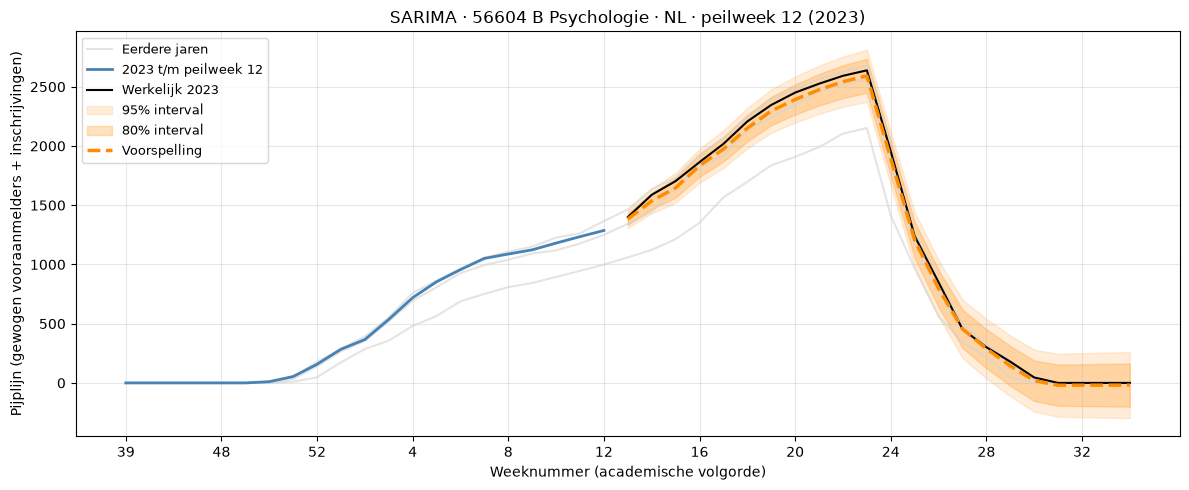

Deel van de weken waarin de werkelijke curve binnen het 95%-interval lag: 100%


In [6]:
volledig = reeks_voor(data_cumulative.copy())
weekcols = get_all_weeks_valid(volledig.columns)
werkelijk_2023 = volledig[volledig["Collegejaar"] == PREDICT_YEAR][weekcols].iloc[0].astype(float)

n_jaren = ts_data.size // PERIODE
start_vj = n_jaren * PERIODE
x_fc = np.arange(PERIODE - len(target_weeks), PERIODE)

fig, ax = plt.subplots(figsize=(12, 5))
for j in range(n_jaren):
    ax.plot(range(PERIODE), ts_data[j * PERIODE:(j + 1) * PERIODE], color="lightgray",
            alpha=0.6, label="Eerdere jaren" if j == 0 else None)
ax.plot(range(ts_data.size - start_vj), ts_data[start_vj:], color="steelblue", linewidth=2,
        label=f"{PREDICT_YEAR} t/m peilweek {PREDICT_WEEK}")
ax.plot(x_fc, werkelijk_2023[target_weeks].values, color="black", linewidth=1.5,
        label=f"Werkelijk {PREDICT_YEAR}")
ax.fill_between(x_fc, fc["lo-95"], fc["hi-95"], alpha=0.15, color="darkorange", label="95% interval")
ax.fill_between(x_fc, fc["lo-80"], fc["hi-80"], alpha=0.25, color="darkorange", label="80% interval")
ax.plot(x_fc, fc["mean"], color="darkorange", linewidth=2.5, linestyle="--", label="Voorspelling")
ax.set_xticks(range(0, PERIODE, 4))
ax.set_xticklabels([weekcols[i] for i in range(0, PERIODE, 4)])
ax.set_xlabel("Weeknummer (academische volgorde)")
ax.set_ylabel("Pijplijn (gewogen vooraanmelders + inschrijvingen)")
ax.set_title(f"SARIMA · {label(PROGRAMMA, NAMEN)} · {HERKOMST} · peilweek {PREDICT_WEEK} ({PREDICT_YEAR})")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

binnen = ((werkelijk_2023[target_weeks].values >= fc["lo-95"]) & (werkelijk_2023[target_weeks].values <= fc["hi-95"])).mean()
print(f"Deel van de weken waarin de werkelijke curve binnen het 95%-interval lag: {binnen:.0%}")


De daling rond week 23 is een eigenschap van de demodata. Omdat hij elk jaar in
dezelfde week zit, neemt SARIMA hem over: dat is precies wat een seizoensmodel doet.
Het laat ook de zwakte zien: SARIMA herhaalt het patroon van eerdere jaren, ook als
dat patroon dit jaar zou veranderen.

## 5. Aannames op data testen


In [7]:
# Aanname 1: het seizoenspatroon herhaalt zich van jaar tot jaar
jaren = sorted(subset["Collegejaar"].astype(int))
curves = ts_data[: n_jaren * PERIODE].reshape(n_jaren, PERIODE)
correlaties = [np.corrcoef(curves[i], curves[i + 1])[0, 1] for i in range(n_jaren - 1)]

pd.DataFrame({
    "Jaarpaar": [f"{jaren[i]} ↔ {jaren[i + 1]}" for i in range(len(correlaties))],
    "Pearson r": np.round(correlaties, 3),
    "Beoordeling": ["✅ sterk (≥ 0,95)" if c >= 0.95 else "⚠️ matig (0,70–0,95)" if c >= 0.7 else "❌ zwak (< 0,70)"
                    for c in correlaties],
})


,Jaarpaar,Pearson r,Beoordeling
0,2020 ↔ 2021,1.000,"✅ sterk (≥ 0,95)"
1,2021 ↔ 2022,0.997,"✅ sterk (≥ 0,95)"


In [8]:
# Aanname 2: genoeg historische jaren per opleiding
counts = (
    data_cumulative[data_cumulative["Examentype"] == "Bachelor"]
    .groupby("Croho groepeernaam")["Collegejaar"].nunique()
)
te_kort = counts[counts < 3]
print(f"Bachelor-opleidingen met < 3 jaar historie: {len(te_kort)} van {len(counts)}")


Bachelor-opleidingen met < 3 jaar historie: 1 van 223


## 6. Wanneer vertrouw je het niet?

| Situatie | Wat te doen? |
|----------|--------------|
| **Pearson r < 0,7** tussen opeenvolgende jaren | Beoordeel de prognose kritisch; vergelijk met het CWF-model |
| **< 3 jaar historie** | SARIMA heeft te weinig seizoenen; gebruik het CWF-model, dat leent van vergelijkbare opleidingen |
| **Uitzonderingsjaar** (bijv. corona) | Sluit het uit via `excluded_data_points` in `configuration.json` |
| **Peilweek < 6** | Lange horizon; rapporteer een bandbreedte, niet één getal |

Vergelijk tijdreeksmodellen op je eigen data met `studentprognose benchmark -d c -w <week>`;
zie [`docs/methodologie/benchmarks.md`](../docs/methodologie/benchmarks.md).
